# Car Price Prediction

**CodeAlpha Data Science Internship — Task 3: Car Price Prediction with Machine Learning**

## Objective
Build a regression model that predicts a used car's selling price based on features
like its age, present (showroom) price, kilometers driven, fuel type, seller type,
transmission, and number of previous owners.

## Dataset
301 records of used car listings, with 8 features and the target variable `Selling_Price`
(in lakhs). Source: car data.csv (provided by CodeAlpha).

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

## 1. Load the Dataset

We read the CSV into a pandas DataFrame and check it loaded correctly.

In [2]:
df = pd.read_csv('car data.csv')
print(df.shape)
df.head()

(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 2. Initial Data Inspection

We check data types, missing values, duplicates, and summary statistics before
cleaning or modeling.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [4]:
# Missing values per column
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

In [5]:
# Number of exact duplicate rows
df.duplicated().sum()

np.int64(2)

In [6]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [7]:
# Number of distinct car names
df['Car_Name'].nunique()

98

**Findings:** The dataset has 301 rows and 9 columns with no missing values. There are
2 exact duplicate rows, and `Car_Name` has 98 distinct values. Both price columns are in
lakhs; `Present_Price` ranges from 0.32 to 92.6 with a median of about 6.4, so the data
covers cheap hatchbacks and a few very expensive cars.

## 3. Data Cleaning

- Remove the 2 duplicate rows found during inspection.
- Drop `Car_Name`: with 98 unique values across only 301 rows, it's too sparse
to encode meaningfully and would risk overfitting.
- Engineer a more useful feature: `Car_Age`, calculated from the `Year` column,
since the age of a car is more directly meaningful for price than the raw year.

In [8]:
# Remove exact duplicate rows found during inspection
df = df.drop_duplicates()
print(df.shape)

(299, 9)


In [9]:
# Drop Car_Name: 98 unique values across ~300 rows is too sparse to encode
df = df.drop(columns=['Car_Name'])
df.columns

Index(['Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type',
       'Selling_type', 'Transmission', 'Owner'],
      dtype='str')

In [10]:
# Convert Year into Car_Age, which is more directly meaningful for predicting price
current_year = 2026
df['Car_Age'] = current_year - df['Year']

# Drop the original Year column now that we have Car_Age
df = df.drop(columns=['Year'])

df.head()

,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


## 4. Exploratory Data Analysis

We visualize the data to understand relationships between features and the
target variable (`Selling_Price`), and to see how categorical features like
fuel type and transmission relate to price.

### 4.1 Target Variable Distribution

Checking the spread and shape of `Selling_Price` before modeling.

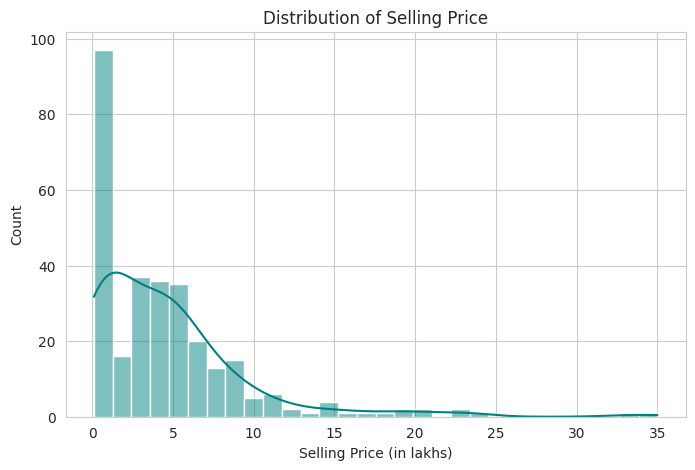

In [11]:
# Distribution of the target variable
plt.figure(figsize=(8, 5))
sns.histplot(df['Selling_Price'], bins=30, kde=True, color='teal')
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price (in lakhs)")
plt.show()

**Observation:** Selling prices are strongly right-skewed. The median is about 3.5 lakhs,
91% of cars sell for under 10 lakhs, and a small number of expensive cars stretch the
tail up to 35 lakhs.

### 4.2 Correlation Heatmap

Checking which numeric features correlate most strongly with `Selling_Price`.

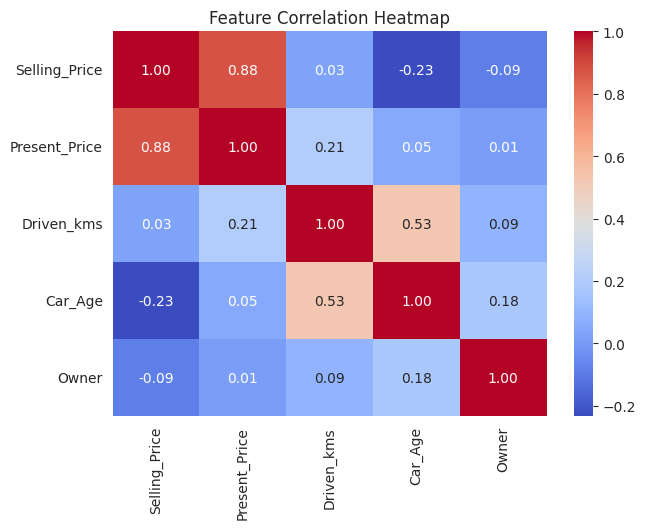

In [12]:
# Correlation heatmap for numeric columns only
numeric_cols = ['Selling_Price', 'Present_Price', 'Driven_kms', 'Car_Age', 'Owner']

plt.figure(figsize=(7, 5))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

**Observation:** `Present_Price` has by far the strongest correlation with `Selling_Price`
(0.88), which makes intuitive sense: a car's original price is a strong anchor for its
resale value. `Car_Age` is weakly negative (-0.23), so older cars tend to sell for
somewhat less. `Driven_kms` (0.03) and `Owner` (-0.09) show almost no linear relationship
with price in this dataset.

### 4.3 Price vs Categorical Features

Comparing `Selling_Price` across `Fuel_Type`, `Selling_type`, and `Transmission`.

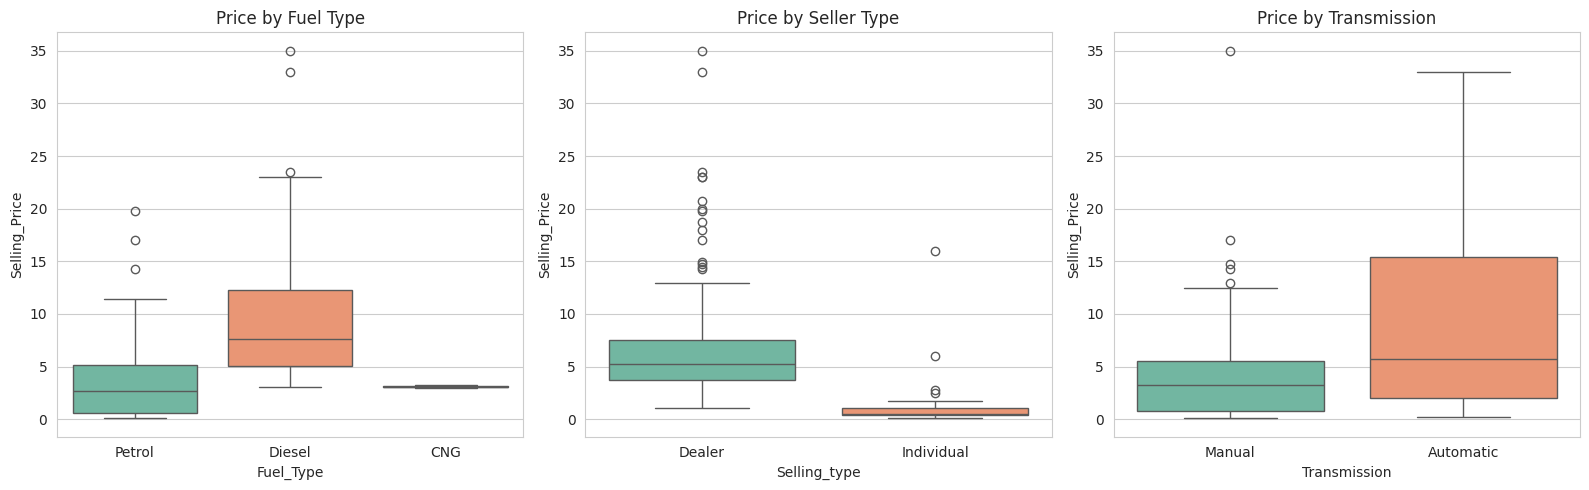

In [13]:
# Boxplots of Selling_Price grouped by each categorical feature
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price', hue='Fuel_Type', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title("Price by Fuel Type")

sns.boxplot(data=df, x='Selling_type', y='Selling_Price', hue='Selling_type', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title("Price by Seller Type")

sns.boxplot(data=df, x='Transmission', y='Selling_Price', hue='Transmission', legend=False, ax=axes[2], palette='Set2')
axes[2].set_title("Price by Transmission")

plt.tight_layout()
plt.show()

**Observation:** Diesel cars have a much higher median price than petrol cars (7.60 vs
2.65 lakhs), dealer-sold cars higher than individual sellers (5.25 vs 0.52), and automatics
higher than manuals (5.75 vs 3.25). These gaps are partly because such cars tend to be more
expensive models in the first place, so they should not be read as the effect of each
feature alone. The groups are also unbalanced: there are only 2 CNG cars and 39 automatics.

### 4.4 Outlier Check

The target is right-skewed, so we check formally for unusually expensive cars using the
IQR rule: anything more than 1.5 × IQR above the third quartile is flagged.

IQR bounds: -6.88 to 13.73 lakhs
Outliers flagged: 16 (5.4% of the data)
Median Present_Price - outliers: 30.61, other cars: 5.87


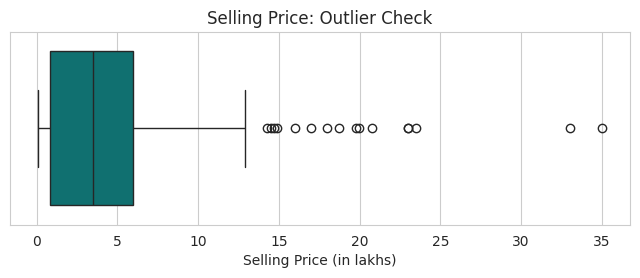

,Present_Price,Driven_kms,Selling_Price
86,92.60,78000,35.00
64,36.23,6000,33.00
63,35.96,47000,23.50
51,30.61,40000,23.00
82,25.39,15000,23.00
96,25.39,29000,20.75
59,35.96,41000,19.99
66,23.15,11000,19.75
62,35.96,78000,18.75
52,19.77,15000,18.00


In [14]:
# IQR method for flagging outliers in Selling_Price
Q1 = df['Selling_Price'].quantile(0.25)
Q3 = df['Selling_Price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Selling_Price'] < lower_bound) | (df['Selling_Price'] > upper_bound)]
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f} lakhs")
print(f"Outliers flagged: {len(outliers)} ({len(outliers) / len(df):.1%} of the data)")

# Compare how expensive these cars were when new, versus everyone else
print(f"Median Present_Price - outliers: {outliers['Present_Price'].median():.2f}, "
      f"other cars: {df.drop(outliers.index)['Present_Price'].median():.2f}")

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df['Selling_Price'], color='teal')
plt.title("Selling Price: Outlier Check")
plt.xlabel("Selling Price (in lakhs)")
plt.show()

outliers[['Present_Price', 'Driven_kms', 'Selling_Price']].sort_values('Selling_Price', ascending=False)

**Observation:** 16 listings (5.4%) are flagged, with selling prices from 14.25 to 35 lakhs.
They look like genuine expensive cars rather than data-entry errors: their median
`Present_Price` is 30.61 lakhs versus 5.87 for the rest, and most are diesel (13 of 16) and
automatic (12 of 16). We keep them for now and test in section 6.3 how much they affect the
models.

## 5. Data Preprocessing

We encode the categorical features into numeric form, separate features from
the target, and split into train/test sets before modeling.

### 5.1 Encoding Categorical Features

In [15]:
# Check the categories in each categorical column before encoding
print(df['Fuel_Type'].unique())
print(df['Selling_type'].unique())
print(df['Transmission'].unique())

<StringArray>
['Petrol', 'Diesel', 'CNG']
Length: 3, dtype: str
<StringArray>
['Dealer', 'Individual']
Length: 2, dtype: str
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str


In [16]:
# One-hot encode the categorical columns
# drop_first=True avoids redundant columns (e.g. if not Petrol and not Diesel, it must be CNG)
df_encoded = pd.get_dummies(df, columns=['Fuel_Type', 'Selling_type', 'Transmission'], drop_first=True)

print(df_encoded.columns.tolist())
df_encoded.head()

['Selling_Price', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Selling_type_Individual', 'Transmission_Manual']


,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,12,False,True,False,True
1,4.75,9.54,43000,0,13,True,False,False,True
2,7.25,9.85,6900,0,9,False,True,False,True
3,2.85,4.15,5200,0,15,False,True,False,True
4,4.60,6.87,42450,0,12,True,False,False,True


### 5.2 Train/Test Split

In [17]:
# Separate features (X) from the target variable (y)
X = df_encoded.drop(columns=['Selling_Price'])
y = df_encoded['Selling_Price']

# Split into 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 239, Test size: 60


### 5.3 Feature Scaling

Scaling puts every feature on a comparable range. It does not change tree-based models or
ordinary linear regression, but it is standard practice and keeps the pipeline ready for
scale-sensitive models such as KNN or SVR.

In [18]:
# Fit the scaler on training data only, then apply it to both sets
# (fitting on test data would leak information and inflate performance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Model Training

We compare three regression models: Linear Regression, Decision Tree, and Random Forest.

### 6.1 Comparison on a Single Train/Test Split

In [19]:
# Define the models to compare
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)

    # Key regression metrics: lower MAE/RMSE is better, higher R² is better
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{name:20s} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R²: {r2:.3f}")

Linear Regression    | MAE: 1.473 | RMSE: 2.525 | R²: 0.753
Decision Tree        | MAE: 1.109 | RMSE: 2.106 | R²: 0.828


Random Forest        | MAE: 1.465 | RMSE: 3.510 | R²: 0.522


- **MAE** (mean absolute error): the average size of a prediction error, in lakhs.
- **RMSE** (root mean squared error): similar, but penalizes large errors more heavily.
- **R²**: the share of the variation in price the model explains (1.0 = perfect).

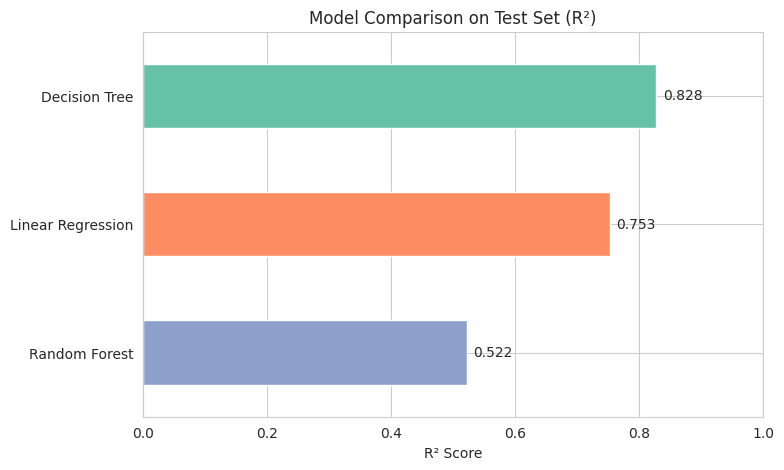

In [20]:
# Compare R² scores visually across models
r2_scores = {name: metrics["R2"] for name, metrics in results.items()}
r2_df = pd.Series(r2_scores).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
r2_df.plot(kind='barh', color=sns.color_palette('Set2'))
plt.xlabel("R² Score")
plt.title("Model Comparison on Test Set (R²)")
plt.xlim(0, 1.0)
for i, v in enumerate(r2_df):
    plt.text(v + 0.01, i, f"{v:.3f}", va='center')
plt.gca().invert_yaxis()
plt.show()

**Observation:** On this one split, Decision Tree scores best (R² 0.828, MAE 1.109), ahead
of Linear Regression (0.753) and Random Forest (0.522). Random Forest is normally at least as
good as a single tree, so this result is surprising. The test set has only about 60 cars, and
a handful of expensive ones can swing the score a lot, so a single split is not enough to
trust. We check with cross-validation next.

### 6.2 Cross-Validation

Cross-validation trains and tests each model on 5 different splits and averages the results,
which is a far more reliable estimate than one split.

**Important detail:** the rows in this file are ordered, and the expensive cars sit close
together (roughly rows 50 to 95). Without shuffling, one fold ends up holding most of the
luxury cars, which the model has never seen. An initial run without shuffling gave unstable
results (even negative R², for example about -20 for Linear Regression), purely because of how
the folds were cut. Setting `shuffle=True` fixes this.

In [21]:
# shuffle=True mixes the rows before splitting, so every fold gets a fair mix of cheap and expensive cars
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    print(f"{name:20s} | CV R² mean: {scores.mean():.3f} | std: {scores.std():.3f} | per fold: {np.round(scores, 2)}")

Linear Regression    | CV R² mean: 0.852 | std: 0.054 | per fold: [0.75 0.87 0.84 0.89 0.91]
Decision Tree        | CV R² mean: 0.923 | std: 0.048 | per fold: [0.83 0.94 0.95 0.94 0.96]


Random Forest        | CV R² mean: 0.859 | std: 0.156 | per fold: [0.56 0.95 0.84 0.96 0.98]


**Observation:** Decision Tree has the best average R² (0.923, std 0.048) and its weakest
fold is still 0.83. Random Forest (0.859) and Linear Regression (0.852) are close behind on
average, but Random Forest is less consistent: it scores between 0.84 and 0.98 on four folds
and 0.56 on one, which drives its high standard deviation (0.156). Decision Tree's lead on the
single split in 6.1 therefore holds up.

### 6.3 Do the Outliers Matter?

We repeat the cross-validation after removing the 16 flagged high-priced cars (section 4.4)
to see how much they affect each model.

In [22]:
# Create a version of the dataset with the outliers removed
df_no_outliers = df[(df['Selling_Price'] >= lower_bound) & (df['Selling_Price'] <= upper_bound)]
print(f"Rows before: {len(df)}, Rows after removing outliers: {len(df_no_outliers)}")

# Rebuild encoding, X, y on the outlier-free data
df_encoded_clean = pd.get_dummies(df_no_outliers, columns=['Fuel_Type', 'Selling_type', 'Transmission'], drop_first=True)
X_clean = df_encoded_clean.drop(columns=['Selling_Price'])
y_clean = df_encoded_clean['Selling_Price']

# Same shuffled folds as before
for name, model in models.items():
    scores = cross_val_score(model, X_clean, y_clean, cv=kf, scoring='r2')
    print(f"{name:20s} | CV R² mean: {scores.mean():.3f} | std: {scores.std():.3f}")

Rows before: 299, Rows after removing outliers: 283
Linear Regression    | CV R² mean: 0.771 | std: 0.082
Decision Tree        | CV R² mean: 0.903 | std: 0.034


Random Forest        | CV R² mean: 0.943 | std: 0.007


**Observation:** Removing the 16 expensive cars helps Random Forest a lot (R² 0.943 with a
tiny std of 0.007) but lowers Decision Tree (0.903) and Linear Regression (0.771). This
suggests Random Forest is very accurate on typical cars and that the expensive ones are what
make its full-dataset score erratic. R² on the two datasets is not directly comparable,
because the spread of prices differs.

We keep the full dataset: these are real listings, and the goal is a model that works across
the whole price range rather than one that quietly ignores expensive cars.

### 6.4 Final Model

We choose the **Decision Tree** trained on the full dataset: it has the best cross-validated
R² (0.923), its worst fold is still strong, and it also led on the single split. Random Forest
is a reasonable alternative for typical-priced cars (6.3) but is less reliable across the full
range.

One caveat: a single unpruned decision tree can overfit and give step-like predictions.
Tuning its depth is a natural next step.

In [23]:
# Final model: Decision Tree (highest cross-validated R² on the full dataset)
best_model_name = "Decision Tree"
best_model = models[best_model_name]
best_model.fit(X_train_scaled, y_train)
y_pred = best_model.predict(X_test_scaled)

## 7. Model Evaluation

### 7.1 Test-Set Performance

In [24]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"{best_model_name} on the held-out test set")
print(f"MAE:  {mae:.3f} lakhs")
print(f"RMSE: {rmse:.3f} lakhs")
print(f"R²:   {r2:.3f}")

Decision Tree on the held-out test set
MAE:  1.109 lakhs
RMSE: 2.106 lakhs
R²:   0.828


**Observation:** On the held-out test set the model explains about 83% of the variation in
price (R² 0.828). Predictions are off by roughly 1.1 lakhs on average (MAE), against a median
selling price of about 3.5 lakhs. RMSE (2.1) is about double the MAE, which means a few large
misses drive much of the error.

### 7.2 Predicted vs Actual Prices

Points closer to the diagonal line are more accurate predictions.

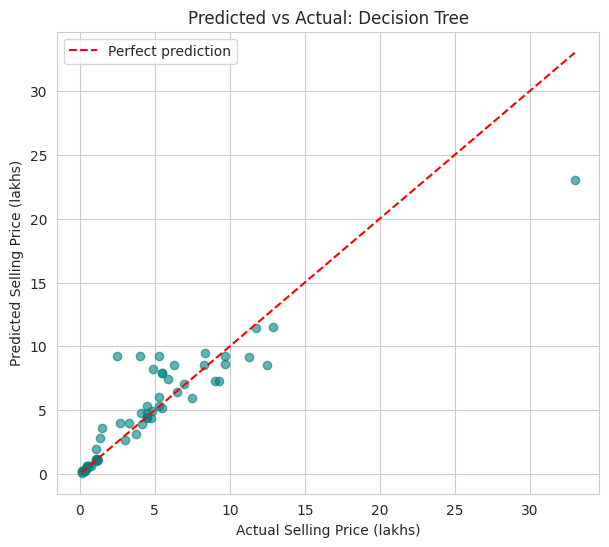

In [25]:
# Scatter plot: predicted vs actual selling price
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
plt.xlabel("Actual Selling Price (lakhs)")
plt.ylabel("Predicted Selling Price (lakhs)")
plt.title(f"Predicted vs Actual: {best_model_name}")
plt.legend()
plt.show()

In [26]:
# The five largest prediction errors
errors = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
errors['Abs_Error'] = (errors['Actual'] - errors['Predicted']).abs()
errors.sort_values('Abs_Error', ascending=False).head(5)

,Actual,Predicted,Abs_Error
18,33.00,23.00,10.00
52,2.50,9.25,6.75
39,4.00,9.25,5.25
4,5.25,9.25,4.00
41,12.50,8.55,3.95


**Observation:** Most points sit close to the diagonal, especially below 10 lakhs where the
bulk of the data is. The biggest misses are the most expensive test car (33 lakhs, predicted
23), three cars that actually sold for 2.5 to 5.25 lakhs but were all predicted at 9.25
(identical predictions suggest they fall in the same leaf of the tree), and one 12.5-lakh car
predicted at 8.55. The model is reliable for typical cars and less so at the extremes, where
there are few training examples.

### 7.3 Feature Importance

Which features does the model rely on most?

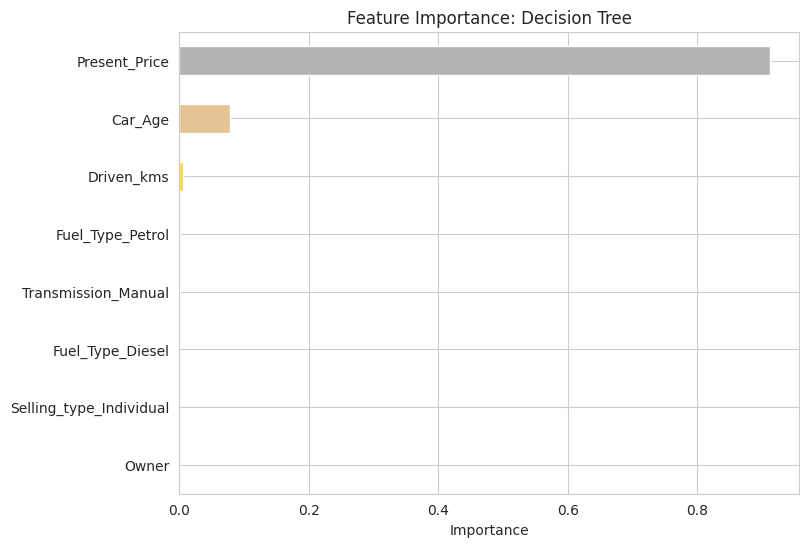

Present_Price              0.912
Car_Age                    0.079
Driven_kms                 0.007
Fuel_Type_Petrol           0.001
Transmission_Manual        0.001
Fuel_Type_Diesel           0.000
Selling_type_Individual    0.000
Owner                      0.000
dtype: float64

In [27]:
# Feature importance from the Decision Tree
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind='barh', color=sns.color_palette('Set2'))
plt.xlabel("Importance")
plt.title("Feature Importance: Decision Tree")
plt.show()

importances.sort_values(ascending=False).round(3)

**Observation:** `Present_Price` accounts for about 91% of the model's importance, `Car_Age`
for about 8%, and `Driven_kms` for under 1%. Every other feature is close to zero. The
fuel-type, seller-type and transmission gaps seen in section 4.3 carry little extra
information once `Present_Price` is known, probably because diesel, automatic and
dealer-sold cars tend to be the more expensive models to begin with.

## 8. Conclusion

- The dataset contains 299 unique used car listings (2 duplicates removed) with no missing
values.
- EDA showed that `Present_Price` is by far the feature most strongly correlated with
`Selling_Price` (0.88), `Car_Age` is weakly negative (-0.23), and kilometers driven and
number of owners show almost no linear relationship. Diesel, automatic and dealer-sold
cars sell for more, largely because they tend to be pricier models to begin with.
- 16 listings (5.4%) are statistical outliers in price. They are genuine expensive cars
(median showroom price 30.6 lakhs), so they were kept.
- Three regression models were compared. On a single train/test split, Decision Tree was
best (R² 0.828) and Random Forest surprisingly weak (0.522). **Shuffled 5-fold
cross-validation confirmed Decision Tree as the best overall** (mean R² 0.923), ahead of
Random Forest (0.859, with one weak fold) and Linear Regression (0.852). A first
cross-validation run without shuffling gave misleading results because the file is ordered
and the expensive cars are clustered together.
- Removing the outliers improved Random Forest to 0.943 and made it very stable, but lowered
the other two models, and R² is not directly comparable across the two datasets. We kept the
full dataset so the model covers the whole price range.
- The final Decision Tree explains about 83% of price variation on the test set, with an
average error of about 1.1 lakhs (MAE) and an RMSE of 2.1 lakhs. It relies almost entirely on
`Present_Price` (91%) and `Car_Age` (8%).
- Predictions are good for typical cars but less reliable for the most expensive ones.

**Limitations:** With about 300 rows, estimates are noisy and a few cars can move the scores
noticeably. Some categories are tiny (2 CNG cars, 39 automatics). The data has no information
on condition, accident history or brand, all of which affect resale prices. A single decision
tree can also overfit and produce step-like predictions.

**Possible next steps:** tune the tree's depth (e.g. `GridSearchCV` on `max_depth` and
`min_samples_leaf`), try gradient boosting models, model the log of the price to handle the
right skew, and extract the brand from `Car_Name` as a feature instead of dropping the column.